In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import mysql.connector as conn
import numpy as np
import pandas as pd; pd.set_option("display.float_format","{:,.2f}".format)
import seaborn as sns; sns.set_theme()
import sqlalchemy
from dotenv import load_dotenv
from sqlalchemy.sql import text

In [2]:
# Takes environment variables from .env.
load_dotenv()

# Credentials for local PostgreSQL database
pg_host = "localhost"
pg_database = "paid_content"
pg_schema = "user_profile"
pg_table = "activity"
pg_user = "postgres"
pg_pass = os.environ["POSTGRES_PASSWORD"]
pg_port = 5432

# Credentials for internal Delfi database
dlf_name_articles = "delfi_articles"
dlf_name_paywall = "paywall"
dlf_host = os.environ["DELFI_DB_HOST"]
dlf_user = os.environ["DELFI_DB_USER"]
dlf_pass = os.environ["DELFI_DB_PASSWORD"]
dlf_port = os.environ["DELFI_DB_PORT"]

In [3]:
dlf_paywall_db = conn.connect(
    host=dlf_host,
    port=dlf_port,
    user=dlf_user,
    password=dlf_pass,
    database=dlf_name_paywall
)

In [4]:
postgresql_url = f"postgresql+psycopg2://{pg_user}:{pg_pass}@{pg_host}:{pg_port}/{pg_database}"

engine = sqlalchemy.create_engine(postgresql_url)

activity_query = text("SELECT * FROM user_profile.activity")

with engine.connect().execution_options(autocommit=True) as conn:
    activity_query_sql = conn.execute(activity_query)

activity_query_data = pd.DataFrame(activity_query_sql.fetchall())

In [5]:
activity_query_data["activity_date"] = activity_query_data["timestamp"].dt.date
activity_query_data["activity_year"] = activity_query_data["timestamp"].dt.year
activity_query_data["activity_month"] = activity_query_data["timestamp"].dt.month

In [6]:
rfv_df = activity_query_data.groupby("user_delfi_id").agg(
    frequency=("activity_date", lambda x: x.nunique()),
    volume=("article_id", lambda x: x.nunique()),
    last_visit=("activity_date", "max"),
    median_active_time=("active_time", "median"),
    median_scroll_depth=("scroll_depth", "median"),
    avg_active_time=("active_time", "mean"),
    avg_scroll_depth=("scroll_depth", "mean")
).reset_index()

In [7]:
# The latest data of activity.
anchor_date = pd.to_datetime("2023-03-05").date()
rfv_df["recency"] = (anchor_date - rfv_df["last_visit"]).dt.days

In [8]:
# Calculate RFV score.
rfv_df["rfv_score"] = (rfv_df["frequency"] * np.sqrt((rfv_df["volume"]))) / (rfv_df["recency"] + 1)
rfv_df["user_delfi_id"] = rfv_df["user_delfi_id"].astype("string")
rfv_df.head()

,user_delfi_id,frequency,volume,last_visit,median_active_time,median_scroll_depth,avg_active_time,avg_scroll_depth,recency,rfv_score
0,1735,3,3,2023-03-01,6.50,39.00,65.25,47.25,4,1.04
1,2140,40,70,2023-03-05,257.50,61.50,273.93,61.66,0,334.66
2,2320,31,43,2023-03-05,88.50,53.50,112.62,47.94,0,203.28
3,2872,7,9,2023-03-05,40.00,100.00,82.00,80.89,0,21.00
4,3069,29,56,2023-03-05,60.00,50.50,111.88,49.91,0,217.02


In [9]:
# User ID and User Delfi ID from Delfi internal database.
user_id_query = """
    SELECT id, delfi_id
    FROM paywall.users
    WHERE delfi_id IS NOT NULL
    """

user_id_data = pd.read_sql(user_id_query, dlf_paywall_db)
user_id_data = user_id_data.astype("string")
user_id_data.head()

,id,delfi_id
0,75757,5
1,2862,6
2,17038,7
3,76102,8
4,89277,9


In [10]:
rfv_df = rfv_df.merge(user_id_data, how="left", left_on="user_delfi_id", right_on="delfi_id").rename(columns={"id": "user_id"})
rfv_df.head()

,user_delfi_id,frequency,volume,last_visit,median_active_time,median_scroll_depth,avg_active_time,avg_scroll_depth,recency,rfv_score,user_id,delfi_id
0,1735,3,3,2023-03-01,6.50,39.00,65.25,47.25,4,1.04,4362,1735
1,2140,40,70,2023-03-05,257.50,61.50,273.93,61.66,0,334.66,14449,2140
2,2320,31,43,2023-03-05,88.50,53.50,112.62,47.94,0,203.28,5856,2320
3,2872,7,9,2023-03-05,40.00,100.00,82.00,80.89,0,21.00,56979,2872
4,3069,29,56,2023-03-05,60.00,50.50,111.88,49.91,0,217.02,56747,3069


# All users

In [66]:
user_sub_data_query = """
    SELECT DISTINCT US.user_id, plan, renewal
    FROM user_subscriptions AS US
    LEFT JOIN subscriptions AS S
    ON US.subscription_id = S.id
    WHERE S.included_in_count = 1
    AND S.service_id IN (1, 3, 4, 9, 10)
    AND valid_till IS NOT NULL
    AND S.sf_category = "Paid subscriptions"
    """

user_sub_data = pd.read_sql(user_sub_data_query, dlf_paywall_db)
user_sub_data = user_sub_data.astype("string")
user_sub_data.head()

,user_id,plan,renewal
0,12,1,0
1,26,1,0
2,27,1,0
3,28,1,1
4,31,1,0


In [12]:
user_sub_data_query = user_sub_data_query.drop_duplicates(subset="user_id", keep=False)

In [13]:
final_data = rfv_df.merge(user_sub_data_query, how="left", on="user_id").drop(columns="delfi_id")
final_data = final_data.astype({"user_delfi_id": "string", "user_id": "string"})

In [14]:
final_b2c_data = final_data[final_data["sf_category"] == "Paid subscriptions"].reset_index().drop(columns="index")
final_b2c_data.head()

,user_delfi_id,frequency,volume,last_visit,median_active_time,median_scroll_depth,avg_active_time,avg_scroll_depth,recency,rfv_score,user_id,sf_category,plan,renewal
0,2140,40,70,2023-03-05,257.50,61.50,273.93,61.66,0,334.66,14449,Paid subscriptions,12,0
1,2320,31,43,2023-03-05,88.50,53.50,112.62,47.94,0,203.28,5856,Paid subscriptions,1,1
2,2872,7,9,2023-03-05,40.00,100.00,82.00,80.89,0,21.00,56979,Paid subscriptions,1,1
3,3069,29,56,2023-03-05,60.00,50.50,111.88,49.91,0,217.02,56747,Paid subscriptions,12,0
4,11878,15,20,2023-03-04,153.50,75.00,207.60,72.75,1,33.54,99419,Paid subscriptions,12,1


In [15]:
rvf_users = final_b2c_data["user_id"].astype(int).to_list()

In [16]:
cursor = dlf_paywall_db.cursor()

parameters_count =", ".join(list(map(lambda x: "%s", rvf_users)))
 
transactions_query = """
    SELECT user_id, COUNT(id), SUM(sum)
    FROM paywall.transactions
    WHERE completion_timestamp IS NOT NULL
    AND sum > 0
    AND user_id IN (%s)
    GROUP BY user_id
    """
transactions_query = transactions_query % parameters_count
    
cursor.execute(transactions_query, rvf_users)

transactions_count = []
user_id = []
amount = []

for user, count, sum in cursor:
    user_id.append(user)
    transactions_count.append(count)
    amount.append(sum)
    
transactions_data = pd.DataFrame({
    "user_id": user_id,
    "transactions_count": transactions_count,
    "total_amount": amount
})

transactions_data["user_id"] = transactions_data["user_id"].astype(str)

cursor.close()

transactions_data.head()

,user_id,transactions_count,total_amount
0,8,66,54.39
1,30,5,88.97
2,34,9,220.61
3,45,11,128.93
4,50,5,61.96


In [17]:
final_b2c_data_V2 = final_b2c_data.merge(transactions_data, how="inner", on="user_id")
final_b2c_data_V2.head()

,user_delfi_id,frequency,volume,last_visit,median_active_time,median_scroll_depth,avg_active_time,avg_scroll_depth,recency,rfv_score,user_id,sf_category,plan,renewal,transactions_count,total_amount
0,2140,40,70,2023-03-05,257.50,61.50,273.93,61.66,0,334.66,14449,Paid subscriptions,12,0,2,48.00
1,2320,31,43,2023-03-05,88.50,53.50,112.62,47.94,0,203.28,5856,Paid subscriptions,1,1,13,88.89
2,2872,7,9,2023-03-05,40.00,100.00,82.00,80.89,0,21.00,56979,Paid subscriptions,1,1,27,101.75
3,3069,29,56,2023-03-05,60.00,50.50,111.88,49.91,0,217.02,56747,Paid subscriptions,12,0,3,73.98
4,11878,15,20,2023-03-04,153.50,75.00,207.60,72.75,1,33.54,99419,Paid subscriptions,12,1,2,40.00


In [18]:
# List of emails of users who gave consent for newsletters.
consent_emails = pd.read_csv("content_emails.txt", header=None, skipfooter=1).rename(columns={0: "email"}).drop_duplicates()

# Querying emails of users from internal Delfi database. 
user_email_query = """
    SELECT id, email
    FROM paywall.users
    WHERE email IS NOT NULL
    """

user_email_data = pd.read_sql(user_email_query, dlf_paywall_db)
user_email_data["id"] = user_email_data["id"].astype("str")
user_email_data = user_email_data.rename(columns={"id": "user_id"})


consent_users = consent_emails.merge(user_email_data, how="left", on="email")
consent_users["consent"] = "1"

final_b2c_data_V2 = final_b2c_data_V2.merge(consent_users[["user_id", "consent"]], how="left", on="user_id").fillna(value={"consent": "0"})
final_b2c_data_V2.head()

,user_delfi_id,frequency,volume,last_visit,median_active_time,median_scroll_depth,avg_active_time,avg_scroll_depth,recency,rfv_score,user_id,sf_category,plan,renewal,transactions_count,total_amount,consent
0,2140,40,70,2023-03-05,257.50,61.50,273.93,61.66,0,334.66,14449,Paid subscriptions,12,0,2,48.00,1
1,2320,31,43,2023-03-05,88.50,53.50,112.62,47.94,0,203.28,5856,Paid subscriptions,1,1,13,88.89,0
2,2872,7,9,2023-03-05,40.00,100.00,82.00,80.89,0,21.00,56979,Paid subscriptions,1,1,27,101.75,0
3,3069,29,56,2023-03-05,60.00,50.50,111.88,49.91,0,217.02,56747,Paid subscriptions,12,0,3,73.98,0
4,11878,15,20,2023-03-04,153.50,75.00,207.60,72.75,1,33.54,99419,Paid subscriptions,12,1,2,40.00,1


Nėra aiškios tiesioginės RFV priklausomybės nuo bendro transakcijų skaičiaus ir visos išleistos sumos. T.y. išimtinai per visą vartotojo gyvavimo laiką didėjant atliktų transakcijų skaičiui ar išleistai sumai RFV nedidėja.

In [ ]:
sns.scatterplot(data=final_b2c_data_V2, x="rfv_score", y="transactions_count")
plt.title("RFV score vs. Total transactions")
plt.xlabel("RFV score")
plt.ylabel("Transactions");

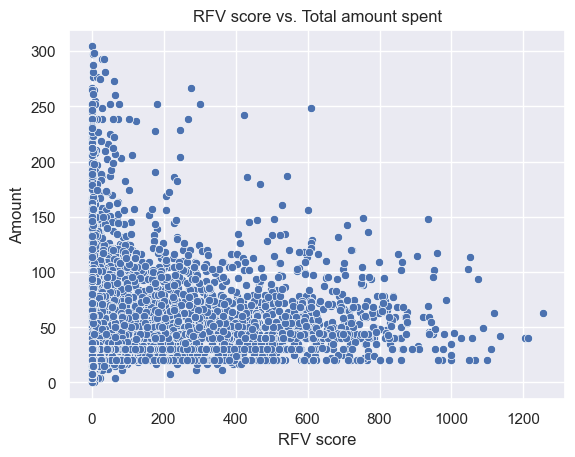

In [20]:
sns.scatterplot(data=final_b2c_data_V2, x="rfv_score", y="total_amount")
plt.title("RFV score vs. Total amount spent")
plt.xlabel("RFV score")
plt.ylabel("Amount");

Pabandžius išskirti atskirai metinių ir mėnesinių planų duomenis, nes jų mokėjimų dažnis ir sumos iš esmės skiriasi, taip pat nebuvo pastebėta aiški priklausomybė.

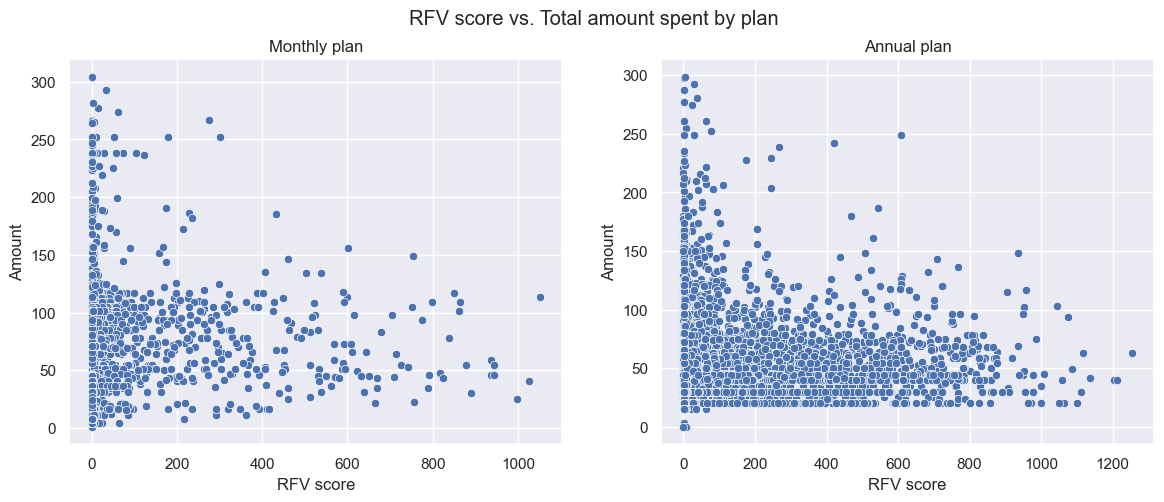

In [21]:
fig, axes = plt.subplots(ncols=2, figsize=(14,5))
sns.scatterplot(ax=axes[0], data=final_b2c_data_V2[final_b2c_data_V2["plan"] == "1"], x="rfv_score", y="total_amount")
sns.scatterplot(ax=axes[1], data=final_b2c_data_V2[final_b2c_data_V2["plan"] == "12"], x="rfv_score", y="total_amount")
fig.suptitle("RFV score vs. Total amount spent by plan")
axes[0].set_title("Monthly plan")
axes[1].set_title("Annual plan")
axes[0].set_xlabel("RFV score")
axes[1].set_xlabel("RFV score")
axes[0].set_ylabel("Amount")
axes[1].set_ylabel("Amount");

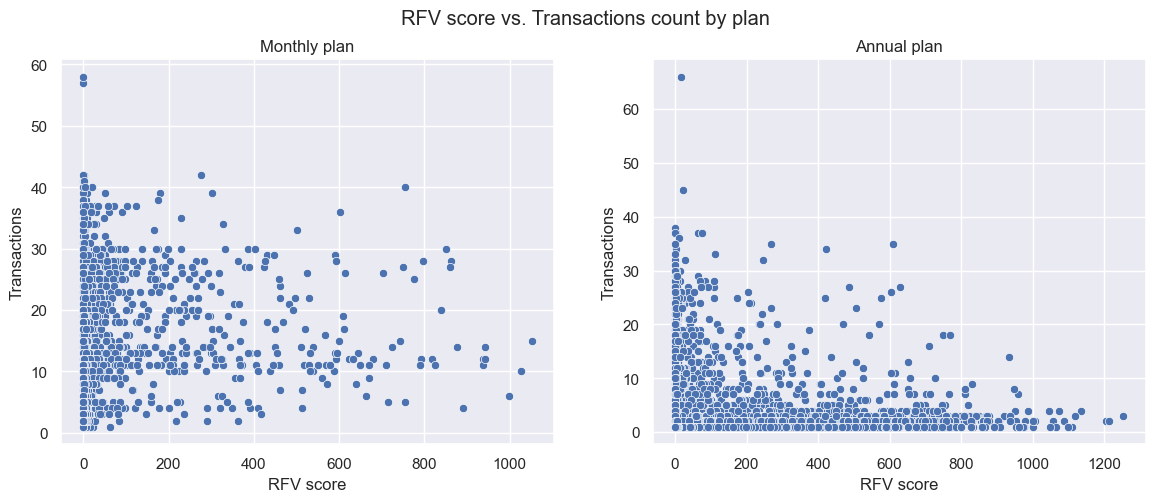

In [22]:
fig, axes = plt.subplots(ncols=2, figsize=(14,5))
sns.scatterplot(ax=axes[0], data=final_b2c_data_V2[final_b2c_data_V2["plan"] == "1"], x="rfv_score", y="transactions_count")
sns.scatterplot(ax=axes[1], data=final_b2c_data_V2[final_b2c_data_V2["plan"] == "12"], x="rfv_score", y="transactions_count")
fig.suptitle("RFV score vs. Transactions count by plan")
axes[0].set_title("Monthly plan")
axes[1].set_title("Annual plan")
axes[0].set_xlabel("RFV score")
axes[1].set_xlabel("RFV score")
axes[0].set_ylabel("Transactions")
axes[1].set_ylabel("Transactions");

Iš transakcijų skaičiaus grafikų matosi, kad yra nemažai taškų, kurių metinių prenumeratų transakcijų skaičius yra daugiau nei 4, kas reiškia, kad daugeliu atveju vartotojas keitėsi iš metinės prenumeratos į mėnesinę arba atvirkščiai. Tai šiek tiek komplikuoja vartotojų išskyrimą pagal planus, todėl sekančiu žingsiu eliminuosiu visus aktyvius vartotojus, kurie yra darę pakeitimą tarp planų.

In [23]:
users_transactions_query = """
    SELECT T.user_id, S.plan, COUNT(T.id) AS transactions_count, SUM(T.sum) AS total_amount
    FROM paywall.transactions AS T
    LEFT JOIN paywall.subscriptions AS S
    ON T.subscription_id = S.id
    WHERE T.completion_timestamp IS NOT NULL
    AND T.sum > 0
    GROUP BY T.user_id, S.plan
    HAVING S.plan IN (1, 12)
    """

users_transactions_data = pd.read_sql(users_transactions_query, dlf_paywall_db)
user_sub_data_query = user_sub_data_query.astype("string")
users_transactions_data.head()

,user_id,plan,transactions_count,total_amount
0,14,1,2,2.00
1,196,1,1,1.00
2,26,1,3,16.98
3,27,1,2,8.99
4,28,1,6,40.95


In [24]:
users_plans_count = users_transactions_data["user_id"].value_counts().reset_index().rename(columns={"index": "user_id", "user_id": "plans_count"})
users_with_one_plan = users_plans_count[users_plans_count["plans_count"] == 1]
users_with_one_plan["user_id"] = users_with_one_plan["user_id"].astype(str)

In [25]:
final_b2c_data_V3 = final_b2c_data_V2.merge(users_with_one_plan, how="inner", on="user_id")

In [26]:
final_b2c_data_V3["plan"].value_counts()

12    6870
1     2720
6        1
Name: plan, dtype: Int64

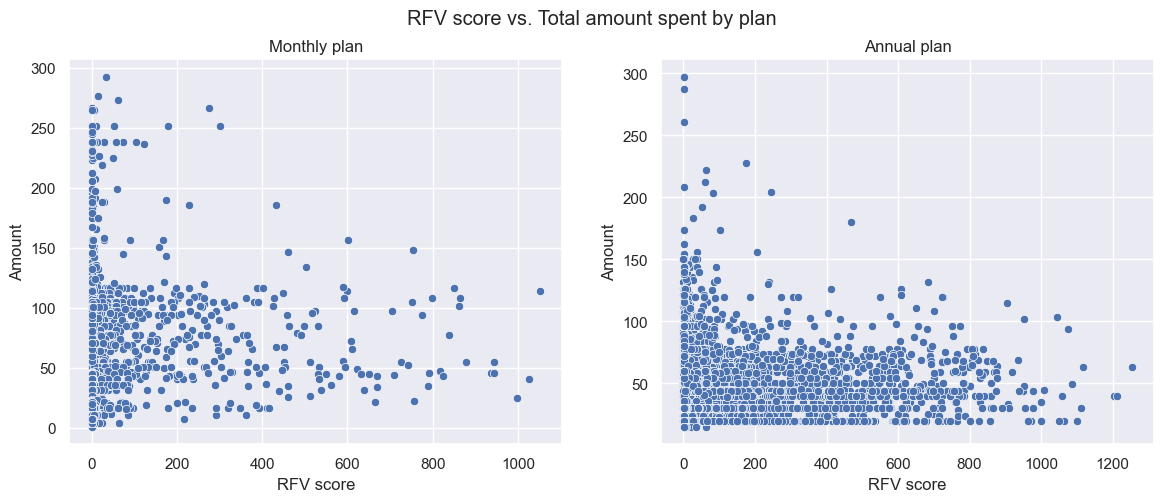

In [27]:
fig, axes = plt.subplots(ncols=2, figsize=(14,5))
sns.scatterplot(ax=axes[0], data=final_b2c_data_V3[final_b2c_data_V3["plan"] == "1"], x="rfv_score", y="total_amount")
sns.scatterplot(ax=axes[1], data=final_b2c_data_V3[final_b2c_data_V3["plan"] == "12"], x="rfv_score", y="total_amount")
fig.suptitle("RFV score vs. Total amount spent by plan ")
axes[0].set_title("Monthly plan")
axes[1].set_title("Annual plan")
axes[0].set_xlabel("RFV score")
axes[1].set_xlabel("RFV score")
axes[0].set_ylabel("Amount")
axes[1].set_ylabel("Amount");

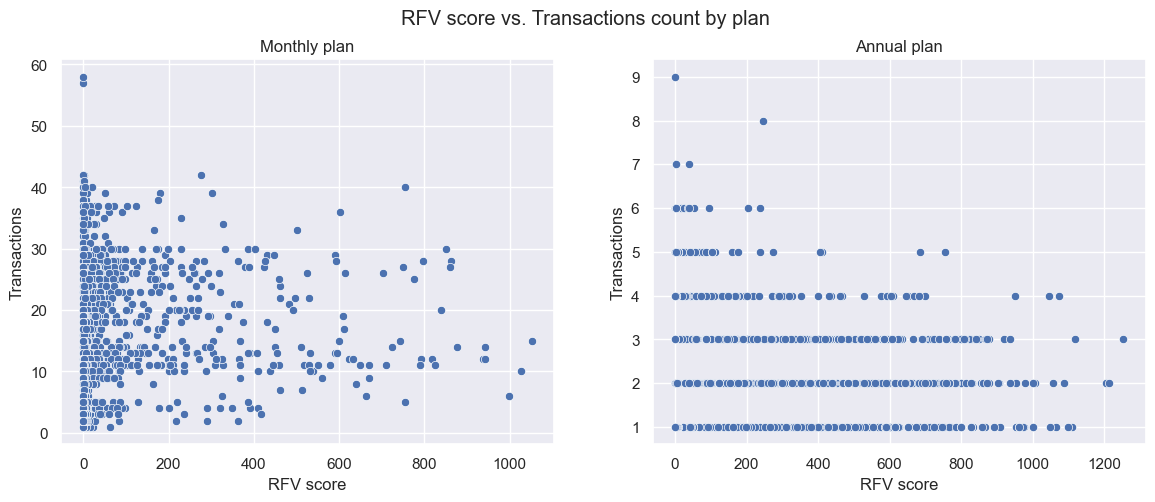

In [28]:
fig, axes = plt.subplots(ncols=2, figsize=(14,5))
sns.scatterplot(ax=axes[0], data=final_b2c_data_V3[final_b2c_data_V3["plan"] == "1"], x="rfv_score", y="transactions_count")
sns.scatterplot(ax=axes[1], data=final_b2c_data_V3[final_b2c_data_V3["plan"] == "12"], x="rfv_score", y="transactions_count")
fig.suptitle("RFV score vs. Transactions count by plan")
axes[0].set_title("Monthly plan")
axes[1].set_title("Annual plan")
axes[0].set_xlabel("RFV score")
axes[1].set_xlabel("RFV score")
axes[0].set_ylabel("Transactions")
axes[1].set_ylabel("Transactions");

Išfiltruoti mėnesinių ir metinių planų RFV, kurie neviršyja vieno standartinio nuokrypio.

In [29]:
rfv_std_annual = final_b2c_data_V3[final_b2c_data_V3["plan"] == "12"]["rfv_score"].std()
rfv_std1_annual = final_b2c_data_V3[(final_b2c_data_V3["plan"] == "12") & (final_b2c_data_V3["rfv_score"] < rfv_std_annual)]

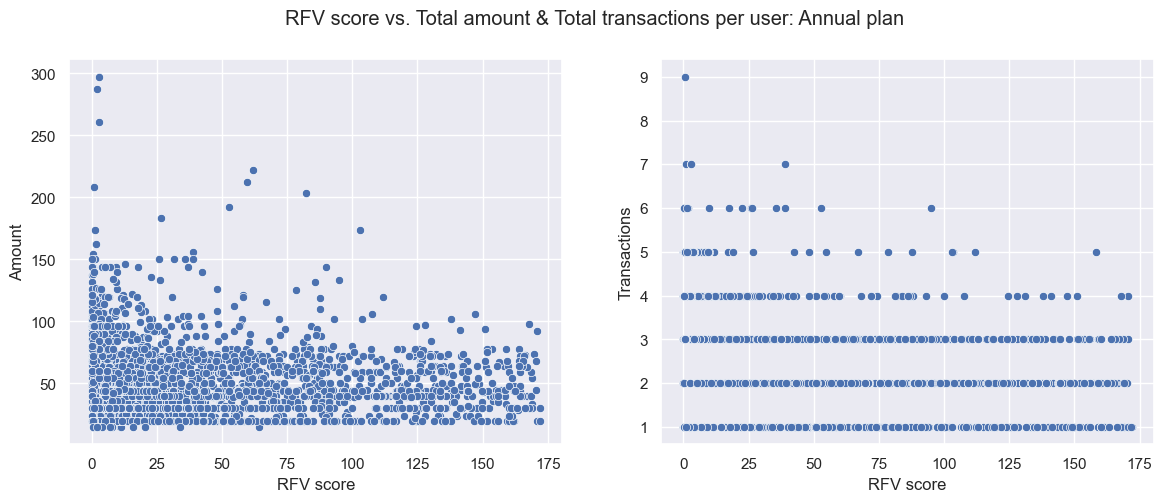

In [30]:
fig, axes = plt.subplots(ncols=2, figsize=(14,5))
sns.scatterplot(ax=axes[0], data=rfv_std1_annual, x="rfv_score", y="total_amount")
sns.scatterplot(ax=axes[1], data=rfv_std1_annual, x="rfv_score", y="transactions_count")
fig.suptitle("RFV score vs. Total amount & Total transactions per user: Annual plan")
axes[0].set_xlabel("RFV score")
axes[1].set_xlabel("RFV score")
axes[0].set_ylabel("Amount")
axes[1].set_ylabel("Transactions");

In [31]:
rfv_std_monthly = final_b2c_data_V3[final_b2c_data_V3["plan"] == "1"]["rfv_score"].std()
rfv_std1_monthly = final_b2c_data_V3[(final_b2c_data_V3["plan"] == "1") & (final_b2c_data_V3["rfv_score"] < rfv_std_monthly)]

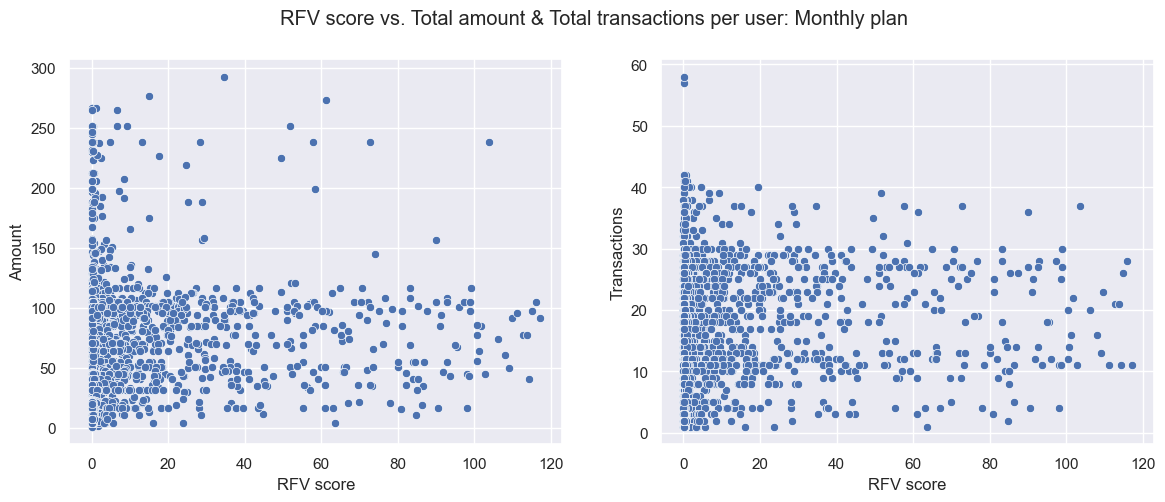

In [32]:
fig, axes = plt.subplots(ncols=2, figsize=(14,5))
sns.scatterplot(ax=axes[0], data=rfv_std1_monthly, x="rfv_score", y="total_amount")
sns.scatterplot(ax=axes[1], data=rfv_std1_monthly, x="rfv_score", y="transactions_count")
fig.suptitle("RFV score vs. Total amount & Total transactions per user: Monthly plan")
axes[0].set_xlabel("RFV score")
axes[1].set_xlabel("RFV score")
axes[0].set_ylabel("Amount")
axes[1].set_ylabel("Transactions");

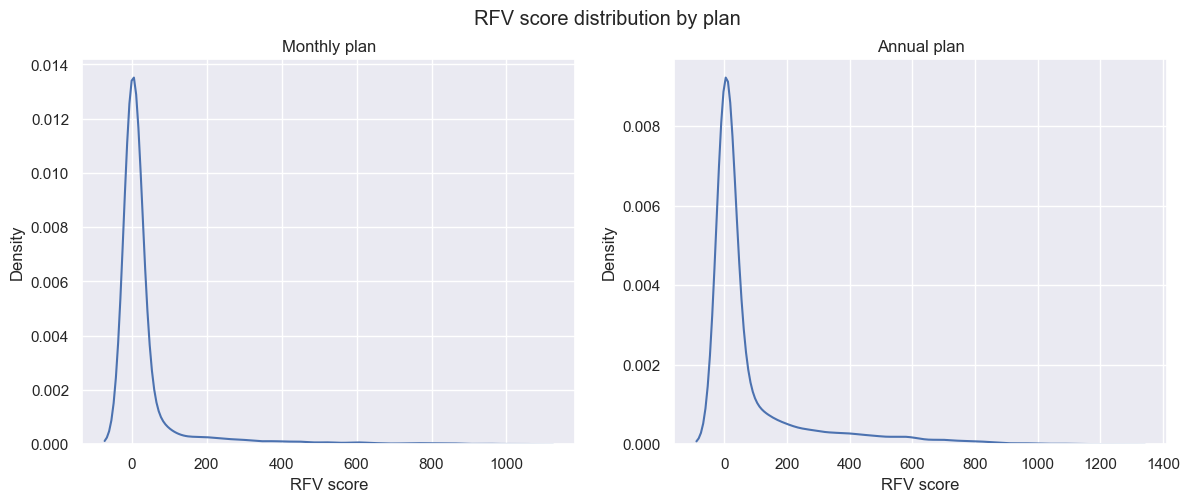

In [33]:
fig, axes = plt.subplots(ncols=2, figsize=(14,5))
sns.kdeplot(ax=axes[0], data=final_b2c_data_V3[final_b2c_data_V3["plan"] == "1"], x="rfv_score")
sns.kdeplot(ax=axes[1], data=final_b2c_data_V3[final_b2c_data_V3["plan"] == "12"], x="rfv_score")
fig.suptitle("RFV score distribution by plan")
axes[0].set_title("Monthly plan")
axes[1].set_title("Annual plan")
axes[0].set_xlabel("RFV score")
axes[1].set_xlabel("RFV score")
axes[0].set_ylabel("Density")
axes[1].set_ylabel("Density");

Iš grafikų matosi, kad RFV indeksas yra pasiskirstęs netolygiai, dėl to naudosiu ne vidurkį, o medianą.

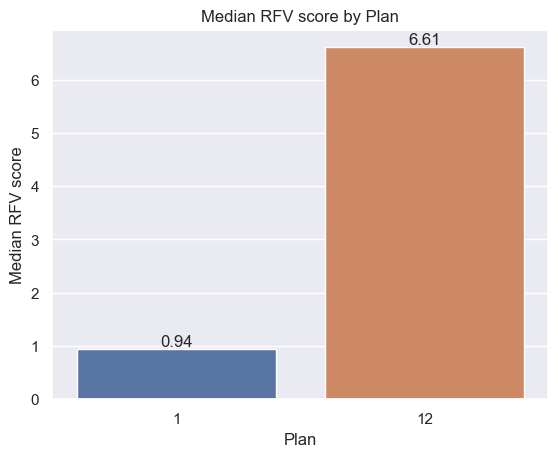

In [34]:
ax = sns.barplot(data=final_b2c_data_V3[(final_b2c_data_V3["plan"] == "1") | (final_b2c_data_V3["plan"] == "12")].groupby("plan")["rfv_score"].median().reset_index(),
            x="plan", y="rfv_score")
ax.bar_label(ax.containers[0], fmt="%.2f")
plt.title("Median RFV score by Plan")
plt.xlabel("Plan")
plt.ylabel("Median RFV score");

In [35]:
pd.DataFrame({
    "Users": final_b2c_data_V3[(final_b2c_data_V3["plan"] == "1") | (final_b2c_data_V3["plan"] == "12")].groupby("plan")["user_id"].count(),
    "Share": (final_b2c_data_V3[(final_b2c_data_V3["plan"] == "1") | (final_b2c_data_V3["plan"] == "12")].groupby("plan")["user_id"].count() 
              / final_b2c_data_V3[(final_b2c_data_V3["plan"] == "1") | (final_b2c_data_V3["plan"] == "12")]["user_id"].count() * 100),
    "RFV": final_b2c_data_V3[(final_b2c_data_V3["plan"] == "1") | (final_b2c_data_V3["plan"] == "12")].groupby("plan")["rfv_score"].median(),
    "Frequency": final_b2c_data_V3[(final_b2c_data_V3["plan"] == "1") | (final_b2c_data_V3["plan"] == "12")].groupby("plan")["frequency"].median(),
    "Recency": final_b2c_data_V3[(final_b2c_data_V3["plan"] == "1") | (final_b2c_data_V3["plan"] == "12")].groupby("plan")["recency"].median(),
    "Volume": final_b2c_data_V3[(final_b2c_data_V3["plan"] == "1") | (final_b2c_data_V3["plan"] == "12")].groupby("plan")["volume"].median(),
    "Active time": final_b2c_data_V3[(final_b2c_data_V3["plan"] == "1") | (final_b2c_data_V3["plan"] == "12")].groupby("plan")["median_active_time"].median(),
    "Scroll depth": final_b2c_data_V3[(final_b2c_data_V3["plan"] == "1") | (final_b2c_data_V3["plan"] == "12")].groupby("plan")["median_scroll_depth"].median(),
    "Transactions": final_b2c_data_V3[(final_b2c_data_V3["plan"] == "1") | (final_b2c_data_V3["plan"] == "12")].groupby("plan")["transactions_count"].median(),
    "Amount": final_b2c_data_V3[(final_b2c_data_V3["plan"] == "1") | (final_b2c_data_V3["plan"] == "12")].groupby("plan")["total_amount"].median(),
}).set_axis(["Plan: Monthly", "Plan: Annual"], axis="index")

,Users,Share,RFV,Frequency,Recency,Volume,Active time,Scroll depth,Transactions,Amount
Plan: Monthly,2720,28.36,0.94,4.00,10.00,5.00,101.50,56.00,15.00,68.84
Plan: Annual,6870,71.64,6.61,9.00,3.00,12.00,108.00,58.00,2.00,43.99


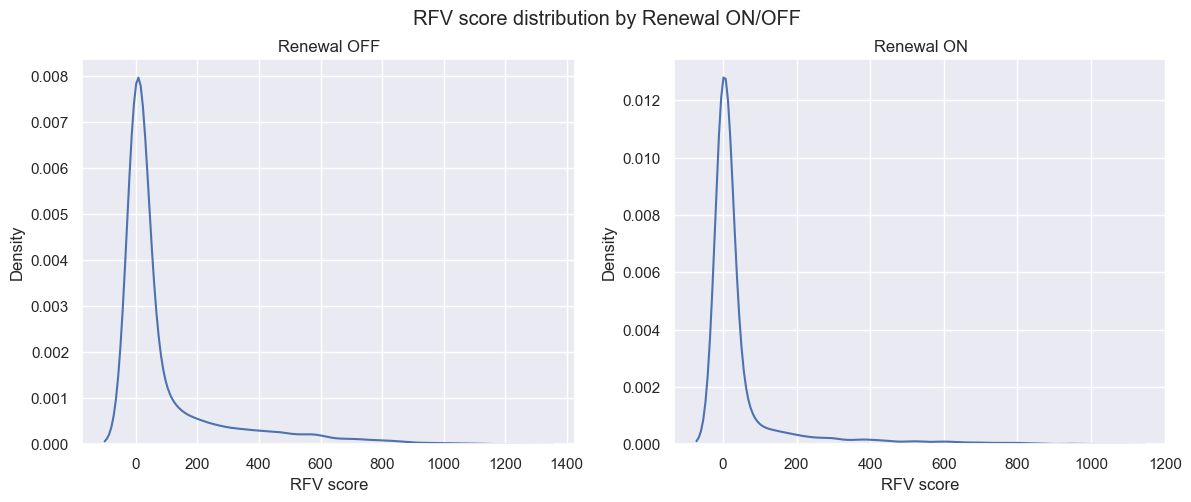

In [36]:
fig, axes = plt.subplots(ncols=2, figsize=(14,5))
sns.kdeplot(ax=axes[0], data=final_b2c_data_V3[final_b2c_data_V3["renewal"] == "0"], x="rfv_score")
sns.kdeplot(ax=axes[1], data=final_b2c_data_V3[final_b2c_data_V3["renewal"] == "1"], x="rfv_score")
fig.suptitle("RFV score distribution by Renewal ON/OFF")
axes[0].set_title("Renewal OFF")
axes[1].set_title("Renewal ON")
axes[0].set_xlabel("RFV score")
axes[1].set_xlabel("RFV score")
axes[0].set_ylabel("Density")
axes[1].set_ylabel("Density");

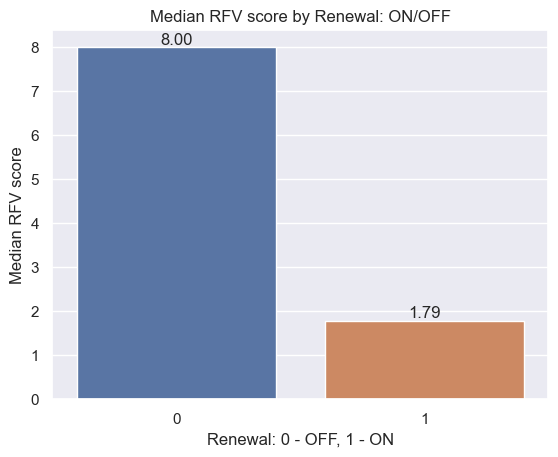

In [37]:
ax = sns.barplot(data=final_b2c_data_V3.groupby("renewal")["rfv_score"].median().reset_index(),
            x="renewal", y="rfv_score")
ax.bar_label(ax.containers[0], fmt="%.2f")
plt.title("Median RFV score by Renewal: ON/OFF")
plt.xlabel("Renewal: 0 - OFF, 1 - ON")
plt.ylabel("Median RFV score");

In [38]:
pd.DataFrame({
    "Users": final_b2c_data_V3.groupby("renewal")["user_id"].count(),
    "Share": final_b2c_data_V3.groupby("renewal")["user_id"].count() / final_b2c_data_V3["user_id"].count() * 100,
    "RFV": final_b2c_data_V3.groupby("renewal")["rfv_score"].median(),
    "Frequency": final_b2c_data_V3.groupby("renewal")["frequency"].median(),
    "Recency": final_b2c_data_V3.groupby("renewal")["recency"].median(),
    "Volume": final_b2c_data_V3.groupby("renewal")["volume"].median(),
    "Active time": final_b2c_data_V3.groupby("renewal")["median_active_time"].median(),
    "Scroll depth": final_b2c_data_V3.groupby("renewal")["median_scroll_depth"].median(),
    "Transactions": final_b2c_data_V3.groupby("renewal")["transactions_count"].median(),
    "Amount": final_b2c_data_V3.groupby("renewal")["total_amount"].median(),
}).set_axis(["Renewal: OFF", "Renewal: ON"], axis="index")

,Users,Share,RFV,Frequency,Recency,Volume,Active time,Scroll depth,Transactions,Amount
Renewal: OFF,4712,49.13,8.00,10.00,3.00,13.00,108.50,57.50,2.00,39.99
Renewal: ON,4879,50.87,1.79,5.00,6.00,7.00,104.00,57.00,4.00,55.86


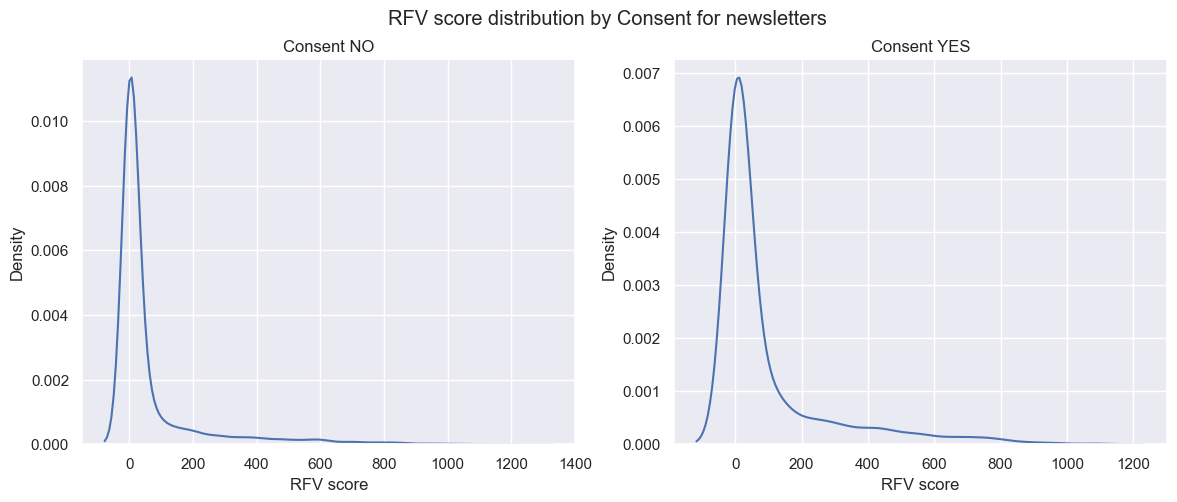

In [39]:
fig, axes = plt.subplots(ncols=2, figsize=(14,5))
sns.kdeplot(ax=axes[0], data=final_b2c_data_V3[final_b2c_data_V3["consent"] == "0"], x="rfv_score")
sns.kdeplot(ax=axes[1], data=final_b2c_data_V3[final_b2c_data_V3["consent"] == "1"], x="rfv_score")
fig.suptitle("RFV score distribution by Consent for newsletters")
axes[0].set_title("Consent NO")
axes[1].set_title("Consent YES")
axes[0].set_xlabel("RFV score")
axes[1].set_xlabel("RFV score")
axes[0].set_ylabel("Density")
axes[1].set_ylabel("Density");

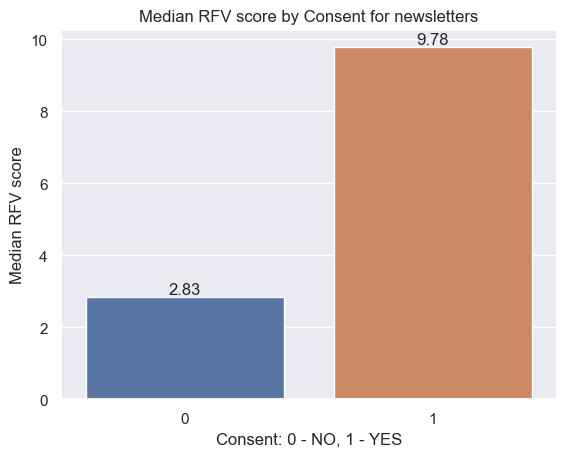

In [40]:
ax = sns.barplot(data=final_b2c_data_V3.groupby("consent")["rfv_score"].median().reset_index(),
            x="consent", y="rfv_score")
ax.bar_label(ax.containers[0], fmt="%.2f")
plt.title("Median RFV score by Consent for newsletters")
plt.xlabel("Consent: 0 - NO, 1 - YES")
plt.ylabel("Median RFV score");

In [41]:
pd.DataFrame({
    "Users": final_b2c_data_V3.groupby("consent")["user_id"].count(),
    "Share": final_b2c_data_V3.groupby("consent")["user_id"].count() / final_b2c_data_V3["user_id"].count() * 100,
    "RFV": final_b2c_data_V3.groupby("consent")["rfv_score"].median(),
    "Frequency": final_b2c_data_V3.groupby("consent")["frequency"].median(),
    "Recency": final_b2c_data_V3.groupby("consent")["recency"].median(),
    "Volume": final_b2c_data_V3.groupby("consent")["volume"].median(),
    "Active time": final_b2c_data_V3.groupby("consent")["median_active_time"].median(),
    "Scroll depth": final_b2c_data_V3.groupby("consent")["median_scroll_depth"].median(),
    "Transactions": final_b2c_data_V3.groupby("consent")["transactions_count"].median(),
    "Amount": final_b2c_data_V3.groupby("consent")["total_amount"].median(),
}).set_axis(["Consent: NO", "Consent: YES"], axis="index")

,Users,Share,RFV,Frequency,Recency,Volume,Active time,Scroll depth,Transactions,Amount
Consent: NO,7469,77.88,2.83,6.00,5.00,8.00,103.00,57.00,2.00,43.99
Consent: YES,2122,22.12,9.78,11.00,3.00,14.00,115.00,58.00,3.00,54.87


# Filtered data

Filtered users who churned or had first time purchase during the period.

In [54]:
print(len(final_b2c_data))
final_b2c_data.head()

11296


,user_delfi_id,frequency,volume,last_visit,median_active_time,median_scroll_depth,avg_active_time,avg_scroll_depth,recency,rfv_score,user_id,sf_category,plan,renewal
0,2140,40,70,2023-03-05,257.50,61.50,273.93,61.66,0,334.66,14449,Paid subscriptions,12,0
1,2320,31,43,2023-03-05,88.50,53.50,112.62,47.94,0,203.28,5856,Paid subscriptions,1,1
2,2872,7,9,2023-03-05,40.00,100.00,82.00,80.89,0,21.00,56979,Paid subscriptions,1,1
3,3069,29,56,2023-03-05,60.00,50.50,111.88,49.91,0,217.02,56747,Paid subscriptions,12,0
4,11878,15,20,2023-03-04,153.50,75.00,207.60,72.75,1,33.54,99419,Paid subscriptions,12,1


In [58]:
filtered_users_query = """
    SELECT P1.user_id, P1.plan, P1.renewal
    FROM (SELECT T.user_id, T.completion_timestamp, S.plan, US.renewal,
        ROW_NUMBER() OVER (PARTITION BY T.user_id ORDER BY T.completion_timestamp) AS row_num
        FROM paywall.transactions AS T
		LEFT JOIN paywall.user_subscriptions AS US
		ON T.user_id = US.user_id
		LEFT JOIN paywall.subscriptions AS S
		ON US.subscription_id = S.id
		WHERE US.service_id IN (1, 3, 4, 9, 10)
		AND S.included_in_count = 1
		AND T.completion_timestamp IS NOT NULL
		AND S.sf_category = "Paid subscriptions"
		AND US.valid_till > "2023-03-05 23:59:59") AS P1
    WHERE P1.row_num = 1
    AND P1.completion_timestamp < "2023-01-01 00:00:00"
    """

filtered_users = pd.read_sql(filtered_users_query, dlf_paywall_db)
filtered_users = filtered_users.astype("string")
filtered_users.head()

,user_id,plan,renewal
0,8,12,0
1,30,12,1
2,34,12,1
3,45,12,0
4,50,12,0


In [55]:
print(len(rfv_df))
rfv_df.head()

13566


,user_delfi_id,frequency,volume,last_visit,median_active_time,median_scroll_depth,avg_active_time,avg_scroll_depth,recency,rfv_score,user_id,delfi_id
0,1735,3,3,2023-03-01,6.50,39.00,65.25,47.25,4,1.04,4362,1735
1,2140,40,70,2023-03-05,257.50,61.50,273.93,61.66,0,334.66,14449,2140
2,2320,31,43,2023-03-05,88.50,53.50,112.62,47.94,0,203.28,5856,2320
3,2872,7,9,2023-03-05,40.00,100.00,82.00,80.89,0,21.00,56979,2872
4,3069,29,56,2023-03-05,60.00,50.50,111.88,49.91,0,217.02,56747,3069


In [59]:
filtered_data = rfv_df.merge(filtered_users, on="user_id")
filtered_data.head()

,user_delfi_id,frequency,volume,last_visit,median_active_time,median_scroll_depth,avg_active_time,avg_scroll_depth,recency,rfv_score,user_id,delfi_id,plan,renewal
0,2140,40,70,2023-03-05,257.50,61.50,273.93,61.66,0,334.66,14449,2140,12,0
1,2320,31,43,2023-03-05,88.50,53.50,112.62,47.94,0,203.28,5856,2320,1,1
2,2872,7,9,2023-03-05,40.00,100.00,82.00,80.89,0,21.00,56979,2872,1,1
3,3069,29,56,2023-03-05,60.00,50.50,111.88,49.91,0,217.02,56747,3069,12,0
4,11878,15,20,2023-03-04,153.50,75.00,207.60,72.75,1,33.54,99419,11878,12,1


In [60]:
filtered_data

,user_delfi_id,frequency,volume,last_visit,median_active_time,median_scroll_depth,avg_active_time,avg_scroll_depth,recency,rfv_score,user_id,delfi_id,plan,renewal
0,2140,40,70,2023-03-05,257.50,61.50,273.93,61.66,0,334.66,14449,2140,12,0
1,2320,31,43,2023-03-05,88.50,53.50,112.62,47.94,0,203.28,5856,2320,1,1
2,2872,7,9,2023-03-05,40.00,100.00,82.00,80.89,0,21.00,56979,2872,1,1
3,3069,29,56,2023-03-05,60.00,50.50,111.88,49.91,0,217.02,56747,3069,12,0
4,11878,15,20,2023-03-04,153.50,75.00,207.60,72.75,1,33.54,99419,11878,12,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10215,1421481,3,3,2023-02-26,16.50,7.50,22.25,8.00,7,0.65,143960,1421481,12,0
10216,1421892,2,2,2023-01-23,30.50,32.00,30.50,32.00,41,0.07,12970,1421892,1,1
10217,1422408,24,53,2023-03-05,147.00,57.50,204.41,56.79,0,174.72,118093,1422408,12,1
10218,1426764,3,3,2023-03-05,122.00,17.00,124.33,25.33,0,5.20,117200,1426764,12,0
